# Step1: Finding the problem

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

C:\Users\Administrator\anaconda3\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
data = pd.read_csv('weight-height.csv')
data.shape

(10000, 3)

In [3]:
data.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  10000 non-null  object 
 1   Height  10000 non-null  float64
 2   Weight  10000 non-null  float64
dtypes: float64(2), object(1)
memory usage: 234.5+ KB


In [5]:
data.duplicated().sum()

0

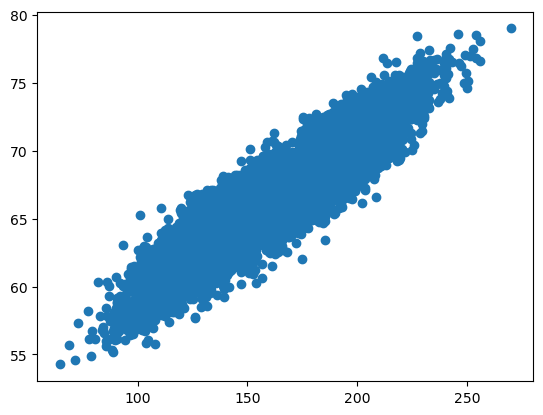

In [6]:
plt.scatter(x=data.Weight, y=data.Height)
plt.show()

In [8]:
data.Weight.corr(data.Height)

0.9247562987409153

# Step2: Separate input(predictor) and output (target) features

In [9]:
X = data[['Height']]
y = data[['Weight']]

# Step3: Splitting the data into training and testing set

In [86]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

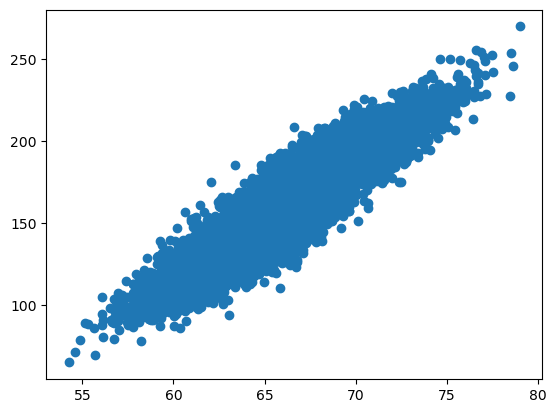

In [87]:
plt.scatter(x=X_train, y=y_train)
plt.show()

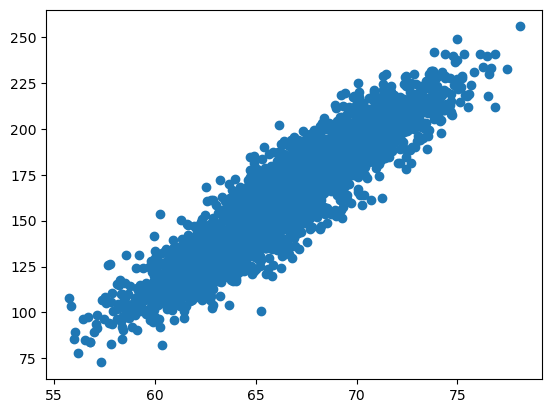

In [88]:
plt.scatter(x=X_test, y=y_test)
plt.show()

# Step4: Model Selection 

In [89]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

# Step5: Fitting / Training the model
        Since we are doing supervised learning.
        We will train the model by saupplying data plus labels (x and y both)

In [90]:
lr.fit(X_train,y_train)

LinearRegression()

In [91]:
lr.coef_

array([[7.69542535]])

In [92]:
lr.intercept_

array([-349.32334861])

# Step6:Prediction on training data

In [93]:
y_pred_train = lr.predict(X_train)

# Step7: Model Performance Evaluation

In [94]:
from sklearn.metrics import mean_squared_error, r2_score

In [95]:
mean_squared_error(y_train,y_pred_train)

149.7046382455686

In [96]:
r2_score(y_train,y_pred_train)

0.8539725668285365

# Step8:Prediction on test data

In [97]:
y_pred_test = lr.predict(X_test)

In [98]:
mean_squared_error(y_test,y_pred_test)

148.36229532793996

In [99]:
r2_score(y_test,y_pred_test)

0.8577298529881874

In [103]:
def weight_predictor(height):
    weight = lr.predict([[height]])
    return weight

In [106]:
height_inch  = float(input("Enter you height in ft"))*12
print(f"Your predicted weight is : {weight_predictor(height_inch)[0][0]*0.456} KG")

Enter you height in ft6
Your predicted weight is : 93.36475823807562 KG


C:\Users\Administrator\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [107]:
data.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


# Multiple Linear Regression: more than 1 input

In [108]:
data.Gender.replace(['Male','Female'], [1,0], inplace=True)

In [109]:
data.head()

,Gender,Height,Weight
0,1,73.847017,241.893563
1,1,68.781904,162.310473
2,1,74.110105,212.740856
3,1,71.730978,220.042470
4,1,69.881796,206.349801


In [110]:
data.corr()

,Gender,Height,Weight
Gender,1.000000,0.691072,0.796723
Height,0.691072,1.000000,0.924756
Weight,0.796723,0.924756,1.000000


In [111]:
X= data[['Gender','Height']]
y = data['Weight']

In [112]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [113]:
mlr = LinearRegression()

In [114]:
mlr.fit(X_train,y_train)

LinearRegression()

In [115]:
mlr.coef_

array([19.40445243,  5.96180802])

In [116]:
mlr.intercept_


-243.94905106192257

In [117]:
y_pred_train = mlr.predict(X_train)

In [119]:
r2_score(y_train,y_pred_train)

0.902443674513295

In [120]:
y_pred_test = mlr.predict(X_test)

In [121]:
r2_score(y_test,y_pred_test)

0.9033211309502138

In [124]:
def weight_predictor(gender,height):
    weight = mlr.predict([[gender,height]])
    return weight

In [127]:
height_inch  = float(input("Enter you height in ft"))*12
gender = int(input("Enter gender 1 for male and 0 for female"))
print(f"Your predicted weight is : {weight_predictor(gender,height_inch)*0.456} KG")

Enter you height in ft5.7
Enter gender 1 for male and 0 for female0
Your predicted weight is : [74.71040946] KG


C:\Users\Administrator\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
